# 2 · Looking at the results

**What you will learn:** which arrays a relaxed `ToF` object contains and how to plot them with plain matplotlib — radial profiles, the 2D shape of the planet, the figure functions, the gravitational moments — and how to compare several models.

PyToF does not ship a plotting module. Everything it computes is a numpy array, and every figure below is a few lines of ordinary matplotlib that you can copy and adapt. (If you work in a Jupyter notebook, `fig, ax = plt.subplots(layout="constrained")` is a good default: it keeps labels from overlapping without further tuning.)

In [1]:
import sys
import pathlib
import inspect

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors

# Optional personal matplotlib style: used if a file mpl_config.py exists in a
# folder above this one, silently ignored otherwise.
for parent in pathlib.Path.cwd().resolve().parents[:4]:
    if (parent / "mpl_config.py").exists():
        sys.path.insert(0, str(parent))
        break
try:
    from mpl_config import apply_mpl_opts

    apply_mpl_opts()
except ImportError:
    pass  # plain matplotlib defaults

from PyToF import ToF
from tutorial_utils import JUPITER_RADIUS, Bessel, LABELS, jupiter, profiles

## What is in a relaxed model

We use the Jupiter polytrope of notebook 1 (`jupiter()` builds and relaxes it). The planet is described by `N` nested level surfaces, ordered **from the outermost inwards**:

| attribute | meaning |
|---|---|
| `X.li` | mean radius of each level surface $l_i$ [m] |
| `X.rhoi` | density on each level surface [kg m⁻³] |
| `X.Pi` | pressure on each level surface [Pa] |
| `X.Js` | gravitational moments, `Js[n]` = $J_{2n}$ (`Js[0]` = −1) |
| `X.figure_functions` | figure functions $s_{2n}(l)$ that describe the shape, see below |
| `X.R_eq_to_R_m`, `X.R_po_to_R_m` | equatorial and polar radius divided by the outermost mean radius |

In [2]:
X = jupiter(N=1024, order=4)
print("shapes:", X.li.shape, X.rhoi.shape, X.Pi.shape)
print("outermost level surface:", X.li[0], "m   innermost:", X.li[-1], "m")

shapes: (1024,) (1024,) (1024,)
outermost level surface: 69920443.46048169 m   innermost: 68281.68306687665 m


For plotting, four derived quantities come up again and again: normalized radius, enclosed mass, density in g/cm³ and pressure in bar. The helper `profiles()` in `tutorial_utils.py` computes them (the enclosed mass is a cumulative sum over shells):

In [3]:
print(inspect.getsource(profiles))

def profiles(X):
    """
    The four per-shell quantities that are usually plotted, as a dict of
    arrays, ordered from the outermost shell inwards, like
    X.li, X.rhoi and X.Pi.

        "r":   mean radius of the shell divided by the outermost one
        "m":   mass enclosed by the shell divided by the total mass
        "rho": density in g/cm^3
        "P":   pressure in bar
    """
    # Mass of every shell between two level surfaces, and the mass inside
    # each shell (cumulative sum from the centre outwards, O(N)):
    shell_mass = (
        4 / 3 * np.pi * (X.li**3 - np.append(X.li[1:], 0) ** 3) * X.rhoi
    )
    enclosed = np.cumsum(shell_mass[::-1])[::-1]
    return {
        "r": X.li / X.li[0],
        "m": enclosed / enclosed[0],
        "rho": X.rhoi / 1000,
        "P": X.Pi / 1e5,
    }



## Radial profiles

Text(0, 0.5, 'density $\\rho$ [g cm$^{-3}$]')

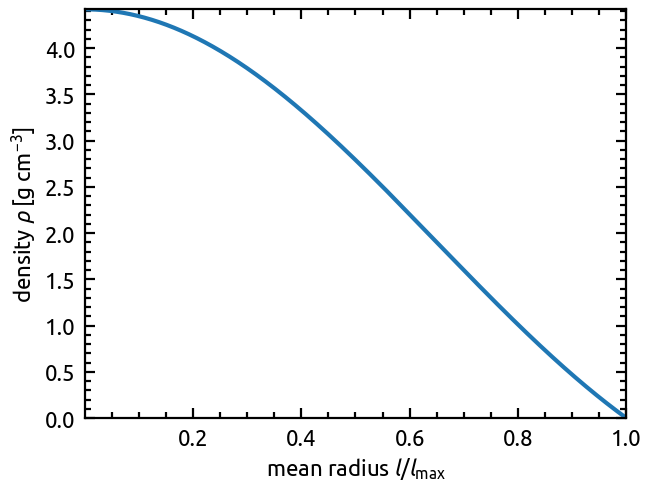

In [4]:
p = profiles(X)

fig, ax = plt.subplots(layout="constrained")
ax.plot(p["r"], p["rho"])
ax.set_xlabel(LABELS["r"])
ax.set_ylabel(LABELS["rho"])

All four quantities at a glance. The pressure spans many orders of magnitude and is best shown on a log axis; the last panel is the barotrope itself, which here reproduces the input $\rho=\sqrt{P/K}$:

Text(0, 0.5, 'density $\\rho$ [g cm$^{-3}$]')

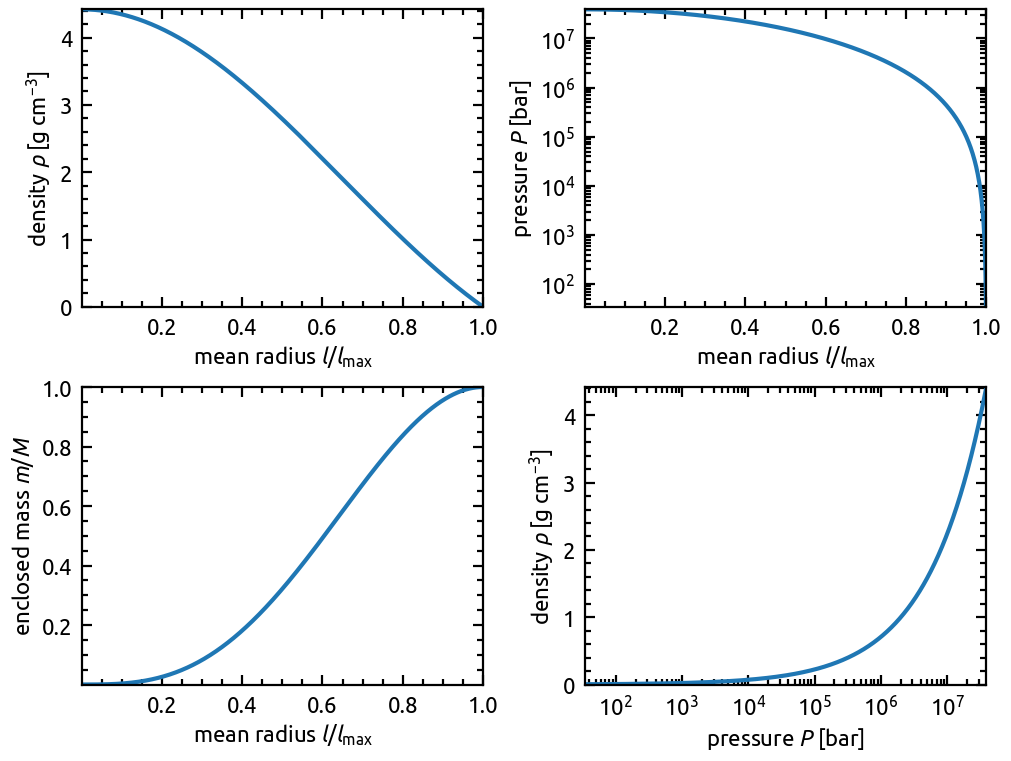

In [5]:
fig, axs = plt.subplots(2, 2, figsize=(10, 7.5), layout="constrained")
axs[0, 0].plot(p["r"], p["rho"])
axs[0, 0].set_xlabel(LABELS["r"]); axs[0, 0].set_ylabel(LABELS["rho"])
axs[0, 1].plot(p["r"], p["P"])
axs[0, 1].set_yscale("log")
axs[0, 1].set_xlabel(LABELS["r"]); axs[0, 1].set_ylabel(LABELS["P"])
axs[1, 0].plot(p["r"], p["m"])
axs[1, 0].set_xlabel(LABELS["r"]); axs[1, 0].set_ylabel(LABELS["m"])
axs[1, 1].plot(p["P"][:-1], p["rho"][:-1])  # skip the surface, where P = 0
axs[1, 1].set_xscale("log")
axs[1, 1].set_xlabel(LABELS["P"]); axs[1, 1].set_ylabel(LABELS["rho"])

## Comparing models

A comparison is just several lines on the same axes. As an example we vary the polytropic index $n$ of the barotrope, $\rho = (P/K)^{n/(n+1)}$ (so $n=1$ is the model above), keeping mass, radius and rotation of Jupiter. We give each model its own color from a colormap and label the colors with a colorbar instead of a legend, which scales to many models:

/home/lumo/Code/PyToF_dev/PyToF/FunctionsToF.py:844: ConvergenceWarning: drho = 2e-05 > 1e-10 = drho_tol after max_iter_update = 100 iterations.
  return _relax(


n     J2            J4
1.0  1.398844e-02  -5.319627e-04
1.2  1.046025e-02  -3.240481e-04
1.5  7.695700e-03  -1.938209e-04
1.8  5.558445e-03  -1.136255e-04
2.0  3.941463e-03  -6.548114e-05


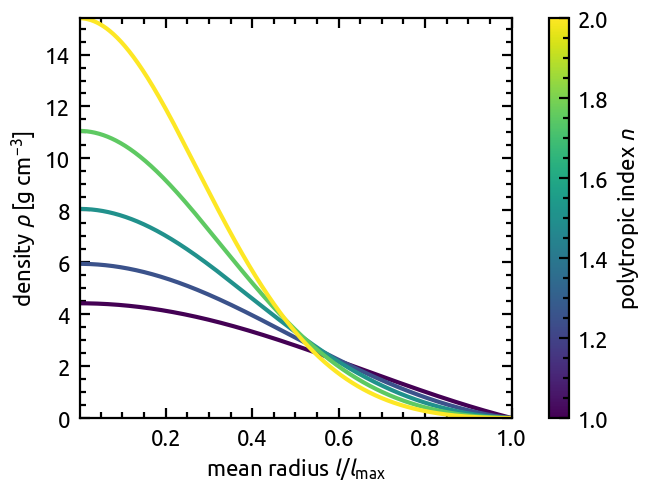

In [6]:
indices = [1.0, 1.25, 1.5, 1.75, 2.0]
models = []
for n in indices:
    Y = ToF(N=1024, order=4, R_ref=JUPITER_RADIUS, baro_param_init=[n])
    Y.set_barotrope(lambda P, param: P ** (param[0] / (param[0] + 1)))
    Y.relax_to_barotrope()
    models.append(Y)

cmap = plt.get_cmap("viridis")
norm = mcolors.Normalize(vmin=min(indices), vmax=max(indices))

fig, ax = plt.subplots(layout="constrained")
for n, Y in zip(indices, models):
    q = profiles(Y)
    ax.plot(q["r"], q["rho"], color=cmap(norm(n)))
ax.set_xlabel(LABELS["r"])
ax.set_ylabel(LABELS["rho"])
fig.colorbar(cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, label="polytropic index $n$")

print("n     J2            J4")
for n, Y in zip(indices, models):
    print(f"{n:3.1f}  {Y.Js[1]:.6e}  {Y.Js[2]:.6e}")

Matching a measured value such as Jupiter's $J_2 = 1.4696\times10^{-2}$ would now select the model(s) that reproduce it: more centrally concentrated models (larger $n$) have a smaller $J_2$. Note that all models cross at about $0.6\,l_\mathrm{max}$, since they have the same mass.

An **inset** is a standard matplotlib inset axes. For instance the pressure of the same models:

Text(0, 0.5, 'density $\\rho$ [g cm$^{-3}$]')

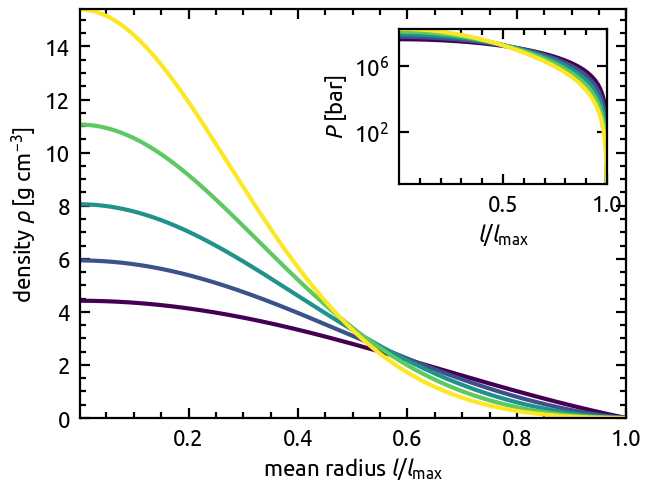

In [7]:
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

fig, ax = plt.subplots(layout="constrained")
ax_ins = inset_axes(ax, width="38%", height="38%", loc="upper right", borderpad=1.0)
for n, Y in zip(indices, models):
    q = profiles(Y)
    ax.plot(q["r"], q["rho"], color=cmap(norm(n)))
    ax_ins.plot(q["r"], q["P"], color=cmap(norm(n)))
ax_ins.set_yscale("log")
ax_ins.set_xlabel(r"$l/l_\mathrm{max}$")
ax_ins.set_ylabel("$P$ [bar]")
ax.set_xlabel(LABELS["r"])
ax.set_ylabel(LABELS["rho"])

## The 2D shape of the planet

`X.get_r_l_mu(mu)` returns the radius of every level surface at the given values of $\mu=\cos\vartheta$ (the cosine of the colatitude $\vartheta$) as an array of shape `(N, len(mu))`. With $x = r\sin\vartheta$ and $z = r\cos\vartheta$ we can draw a cross-section through the rotation axis, coloring each level surface by its density. Jupiter is a fast rotator, so the flattening is clearly visible:

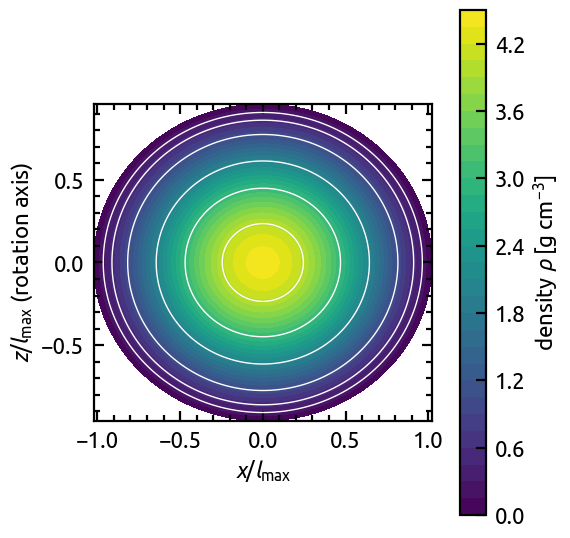

In [8]:
theta = np.linspace(0, 2 * np.pi, 721)  # 0..pi: right half, pi..2pi: left half
r = X.get_r_l_mu(np.cos(theta))  # (N, len(theta)), in m
xs, zs = r * np.sin(theta) / X.li[0], r * np.cos(theta) / X.li[0]
rho_shell = np.outer(X.rhoi / 1000, np.ones_like(theta))

fig, ax = plt.subplots(figsize=(5.6, 6.4), layout="constrained")
cs = ax.contourf(xs, zs, rho_shell, levels=40, cmap="viridis")
ax.contour(xs, zs, rho_shell, levels=[0.25, 0.5, 1, 2, 3, 4], colors="white", linewidths=1.0)
ax.set_aspect("equal")
ax.set_xlabel(r"$x / l_\mathrm{max}$")
ax.set_ylabel(r"$z / l_\mathrm{max}$ (rotation axis)")
fig.colorbar(cs, ax=ax, label=LABELS["rho"], shrink=0.8)

The same information quantitatively: how much does each level surface deviate from a sphere of its own mean radius $l$? The relative deviation $r(\vartheta)/l - 1$ is largest for the outermost surface (about 2% at the equator, $-4$% at the poles) and decreases towards the core, but only by about a factor of 1.5 — the interior of a fast rotator is far from spherical.

R_eq/R_m = 1.02248   R_po/R_m = 0.95724   flattening 1 - R_po/R_eq = 0.0638


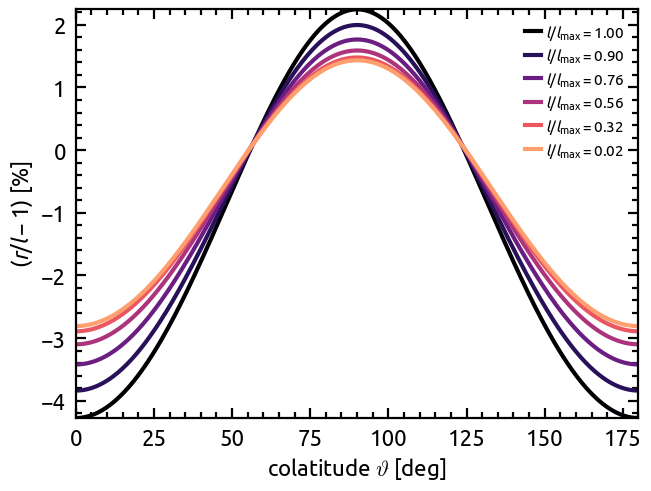

In [9]:
theta = np.linspace(0, np.pi, 361)
r = X.get_r_l_mu(np.cos(theta))
levels = [0, 100, 250, 450, 700, 1000]  # indices of the level surfaces
cmap_l = plt.get_cmap("magma")

fig, ax = plt.subplots(layout="constrained")
for k, i in enumerate(levels):
    ax.plot(np.degrees(theta), 100 * (r[i] / X.li[i] - 1), color=cmap_l(0.8 * k / (len(levels) - 1)), label=f"$l/l_\\mathrm{{max}} = {X.li[i] / X.li[0]:.2f}$")
ax.set_xlabel(r"colatitude $\vartheta$ [deg]")
ax.set_ylabel(r"$(r/l - 1)$ [%]")
ax.set_xlim(0, 180)
ax.legend(frameon=False, fontsize=11)
print(f"R_eq/R_m = {X.R_eq_to_R_m:.5f}   R_po/R_m = {X.R_po_to_R_m:.5f}   flattening 1 - R_po/R_eq = {1 - X.R_po_to_R_m / X.R_eq_to_R_m:.4f}")

## Figure functions

The shape is stored as the *figure functions* $s_{2n}(l)$: the level surface is $r(l,\mu) = l\,\bigl[1 + \sum_n s_{2n}(l)\,P_{2n}(\mu)\bigr]$ with Legendre polynomials $P_{2n}$ (Eq. B.1 of arXiv:1708.06177). `X.figure_functions[n]` holds $s_{2n}$; note that, unlike `X.li`, these arrays run from the **innermost** to the outermost surface. Normalized to their largest value:

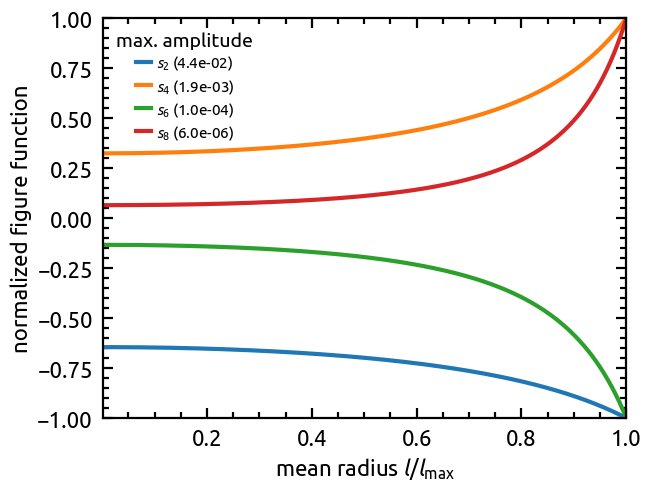

In [10]:
fig, ax = plt.subplots(layout="constrained")
for n in range(1, len(X.figure_functions)):
    s = X.figure_functions[n][::-1]  # flip: outermost first, like X.li
    ax.plot(X.li / X.li[0], s / np.max(np.abs(s)), label=rf"$s_{{{2 * n}}}$ ({np.max(np.abs(s)):.1e})")
ax.set_xlabel(LABELS["r"])
ax.set_ylabel("normalized figure function")
ax.legend(title="max. amplitude", frameon=False, fontsize=11)

## The gravitational moments

$|J_{2n}|$ falls off by roughly an order of magnitude per step, so a log axis is natural. Here with the Bessel reference and, as a lower panel, the relative error with the error estimate from `get_Js_errors()` (10th order, since the lower orders are far from the reference for the higher moments):

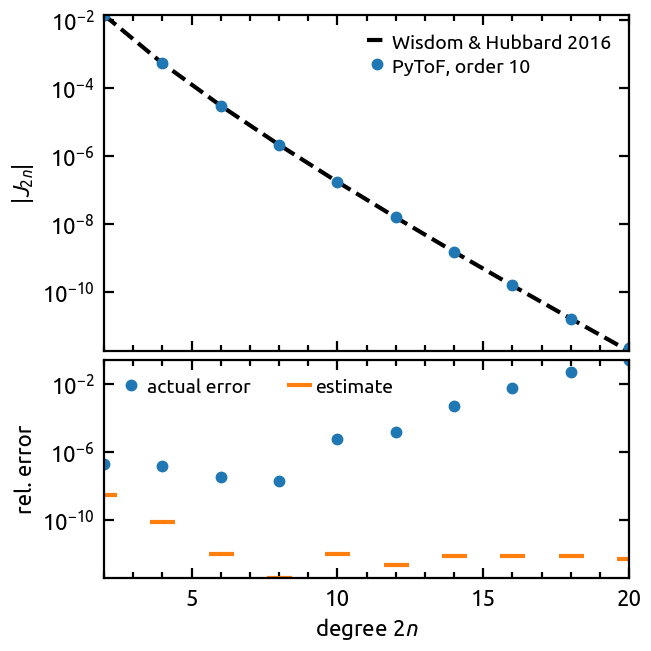

In [11]:
Z = jupiter(N=2048, order=10)
Z.get_Js_errors()
n = np.arange(1, 11)

fig, (ax, ax_err) = plt.subplots(2, 1, figsize=(6.4, 6.4), layout="constrained", sharex=True, height_ratios=[2, 1.3])
ax.plot(2 * n, np.abs(Bessel[1:]), "k--", label="Wisdom & Hubbard 2016", zorder=1)
ax.plot(2 * n, np.abs(Z.Js[1:]), "o", label="PyToF, order 10")
ax.set_yscale("log")
ax.set_ylabel(r"$|J_{2n}|$")
ax.legend(frameon=False)

ax_err.plot(2 * n, np.abs(Z.Js[1:] / Bessel[1:] - 1), "o", label="actual error")
ax_err.plot(2 * n, Z.Js_errors[1:], "_", markersize=18, markeredgewidth=3, label="estimate")
ax_err.set_yscale("log")
ax_err.set_xlabel("degree $2n$")
ax_err.set_ylabel("rel. error")
ax_err.legend(frameon=False, ncol=2)

## Saving figures

Figures are saved with matplotlib's `savefig`; nothing PyToF-specific is involved:

```python
fig.savefig("density_profile.png", dpi=200)   # raster
fig.savefig("density_profile.pdf")            # vector, for papers
```

## Takeaways

* `X.li`, `X.rhoi`, `X.Pi` are the profiles (outermost shell first), `X.figure_functions` the shape (innermost first), `X.get_r_l_mu(mu)` the 2D surfaces.
* One small function (`profiles()`) turns them into plot-ready arrays; everything else is standard matplotlib.
* To compare models, loop over them, and label with a legend or a colorbar.

Next: [3 · your own planet](03_your_own_planet.ipynb).